In [1]:
#covarianza indica la direccion de la asociacion lineal
# cov = valores_indep.cov(valor_dep)
# corr = valores_indep.corr (valor_dep)
# relacion psitiva fuerte -> 0.8996 = 1 se aproxima


In [2]:
# Base de datos :

import pandas as pd

df = pd.read_excel('01_MATRICULAS_ED_SUPERIOR_ARICA_Y_PARINACOTA_2021.xlsx')
df

,ID,GENERO,EDAD,RANGO EDAD,AÑO INGRESO,SEMESTRE INGRESO,TIPO DE INSTITUCION,NOMBRE DE INSTITUCION,ACREDITACION INSTITUCIONAL,PERIODO DE ACREDITACION,...,NIVEL CARRERA,AREA CONOCIMIENTO,DURACION PLAN DE ESTUDIO (SEMESTRES),DURACION PROCESO TITULACION (SEMESTRES),DURACION TOTAL CARRERA (SEMESTRES),VALOR MATRICULA (PESOS),VALOR ARANCEL (PESOS),REGION SEDE,PROVINCIA SEDE,COMUNA SEDE
0,1,Femenino,22,20 a 24,2019,Primer semestre,Centros de Formacion Tecnica,CFT DE TARAPACA,NO ACREDITADA,NaN,...,Carreras Tecnicas,Salud,5,1,5,120000,1823000,Arica y Parinacota,Arica,Arica
1,27,Femenino,26,25 a 29,2020,Primer semestre,Institutos Profesionales,IP SANTO TOMAS,ACREDITADA,20/01/2021 AL 20/01/2026,...,Carreras Profesionales,Administracion y Comercio,4,0,4,89000,1855000,Arica y Parinacota,Arica,Arica
2,38,Masculino,24,20 a 24,2015,Primer semestre,Universidades CRUCH,UNIVERSIDAD DE TARAPACA,ACREDITADA,22/11/2017 AL 22/11/2022,...,Carreras Profesionales,Salud,10,1,10,155000,3533000,Arica y Parinacota,Arica,Arica
3,193,Femenino,23,20 a 24,2016,Primer semestre,Universidades CRUCH,UNIVERSIDAD DE TARAPACA,ACREDITADA,22/11/2017 AL 22/11/2022,...,Carreras Profesionales,Salud,10,1,10,155000,3533000,Arica y Parinacota,Arica,Arica
4,472,Femenino,20,20 a 24,2019,Primer semestre,Universidades CRUCH,UNIVERSIDAD DE TARAPACA,ACREDITADA,22/11/2017 AL 22/11/2022,...,Carreras Profesionales,Educacion,10,1,10,155000,2857000,Arica y Parinacota,Arica,Arica
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14111,1048175,Masculino,19,15 a 19,2020,Primer semestre,Universidades CRUCH,UNIVERSIDAD DE TARAPACA,ACREDITADA,22/11/2017 AL 22/11/2022,...,Carreras Profesionales,Administracion y Comercio,10,1,10,155000,3145000,Arica y Parinacota,Arica,Arica
14112,1048202,Femenino,19,15 a 19,2020,Primer semestre,Universidades CRUCH,UNIVERSIDAD DE TARAPACA,ACREDITADA,22/11/2017 AL 22/11/2022,...,Carreras Profesionales,Educacion,8,2,8,155000,2857000,Arica y Parinacota,Arica,Arica
14113,1048240,Masculino,24,20 a 24,2021,Primer semestre,Institutos Profesionales,IP SANTO TOMAS,ACREDITADA,20/01/2021 AL 20/01/2026,...,Carreras Profesionales,Administracion y Comercio,8,0,8,89000,1817000,Arica y Parinacota,Arica,Arica
14114,1048332,Femenino,24,20 a 24,2021,Primer semestre,Universidades CRUCH,UNIVERSIDAD DE TARAPACA,ACREDITADA,22/11/2017 AL 22/11/2022,...,Carreras Profesionales,Salud,14,4,14,155000,5595000,Arica y Parinacota,Arica,Arica


In [3]:
#Covarianza
corv = df['VALOR MATRICULA (PESOS)'].cov(df['VALOR ARANCEL (PESOS)'])
print(corv)
print("la covarianza seria directa")
print("")

# Correlacion
corr = df['VALOR MATRICULA (PESOS)'].corr(df['VALOR ARANCEL (PESOS)'])
print(corr)
print("r = 0,50 -> correlacion positiva MODERADA (entre 0,4 y 0,7)")

30456470119.178127
la covarianza seria directa

0.499595892974239
r = 0,50 -> correlacion positiva MODERADA (entre 0,4 y 0,7)


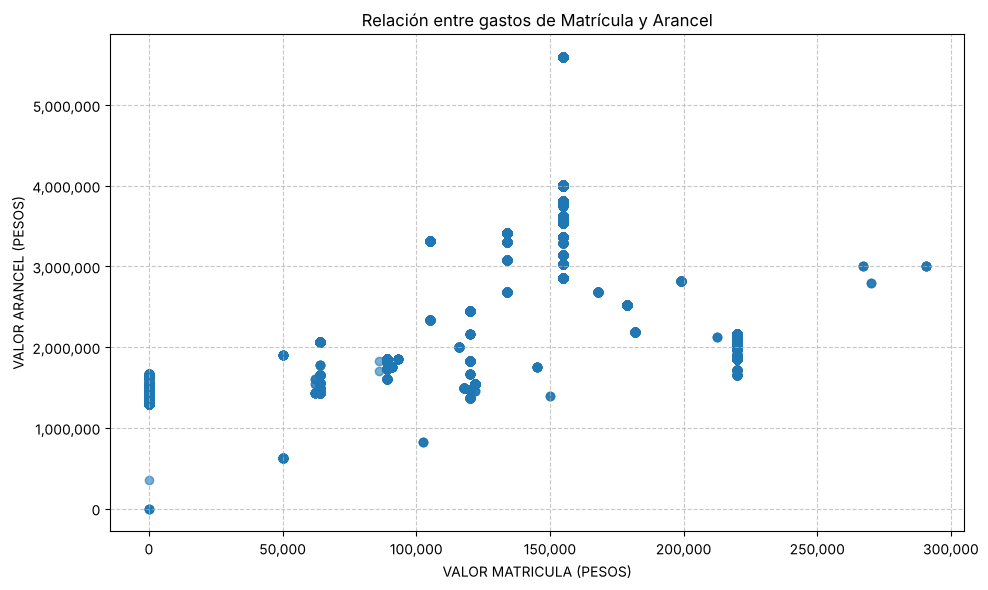

In [4]:
# generar grafico
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

df_ASOC = pd.read_excel('01_MATRICULAS_ED_SUPERIOR_ARICA_Y_PARINACOTA_2021.xlsx')

#Declaramos las variables
valores_indep = df_ASOC['VALOR MATRICULA (PESOS)']
valor_dep = df_ASOC['VALOR ARANCEL (PESOS)']

#Grafico
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(valores_indep, valor_dep, alpha=0.6)

#Personalizacion
ax.set_title('Relación entre gastos de Matrícula y Arancel')
ax.set_xlabel('VALOR MATRICULA (PESOS)')
ax.set_ylabel('VALOR ARANCEL (PESOS)')

# Formatear ejes para evitar la notación científica y mostrar los números completos con separadores de miles
ax.get_xaxis().set_major_formatter(ticker.FuncFormatter(lambda x, p: format(int(x), ',')))
ax.get_yaxis().set_major_formatter(ticker.FuncFormatter(lambda y, p: format(int(y), ',')))

ax.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [5]:
# Obtener el modelo con NUMPY
import numpy as np
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import pandas as pd

# Base de datos :

df_ASOC = pd.read_excel('01_MATRICULAS_ED_SUPERIOR_ARICA_Y_PARINACOTA_2021.xlsx')

# Valores
Valores_indep = df_ASOC['VALOR MATRICULA (PESOS)']
Valores_dep = df_ASOC['VALOR ARANCEL (PESOS)']



# Pasamos los arreglos de datos correctos y el grado 1 para regresión lineal
modelo_lineal = np.polyfit(Valores_indep, Valores_dep, 1)
pendiente, intercepto = modelo_lineal

# Coeficiente de determinación
predicciones = np.polyval(modelo_lineal, Valores_indep)
R2= r2_score(Valores_dep, predicciones)

print(f'pendiente: {pendiente:.3f}')
print(f'intercepto: {intercepto:.3f}')
print(f'la ecuacion del modelo lineal es y = {pendiente:.3f}x + {intercepto:.3f}')
print(f'El coeficiente de determinación es {R2*100:.1f}%')

# Interpretacion de los Datos:

 # Modelo lineal: y = 7.502x + 1.724.71
 # pendiente: 7.502
 # intercepto: 1.724.71
 # identificacion de las variables, V.i y V.D
 # 3 el (n) es el punto de incio de todo. 6+
 # Todo los datos del reslutado inerpretarlos uno por uno.



pendiente: 7.502
intercepto: 1724716.316
la ecuacion del modelo lineal es y = 7.502x + 1724716.316
El coeficiente de determinación es 25.0%


In [6]:
# Interpretación de los resultados de la regresión lineal:

# El valor de la pendiente es: 7.502.
# Esto significa que por cada peso ($1) de incremento en el VALOR MATRÍCULA (variable independiente),
# el VALOR ARANCEL (variable dependiente) aumenta en promedio $7.50 pesos.

# El valor del intercepto es: 1,724,716.316.
# Esto significa que si el VALOR MATRÍCULA fuera de $0 pesos, el VALOR ARANCEL base estimado comenzaría en $1,724,716 pesos.

Probabilidad conjunta y
condicional en Python

1. Probabilidad simple: ¿Cuál es la probabilidad de que, al seleccionar al azar a un estudiante de la base de datos, este pertenezca a la institución UNIVERSIDAD DE TARAPACA?

 2. Probabilidad conjunta: ¿Cuál es la probabilidad de que, al seleccionar al azar a un estudiante, este sea del género Femenino y esté matriculado en un nivel de carrera de Carreras Técnicas?

3. Probabilidad condicional: Si se sabe que el estudiante seleccionado pertenece al área de conocimiento de Salud, ¿cuál es la probabilidad de que esté matriculado en una institución con Acreditación Institucional (ACREDITADA)?


In [7]:
import pandas as pd
df = pd.read_excel('01_MATRICULAS_ED_SUPERIOR_ARICA_Y_PARINACOTA_2021.xlsx')

# Tabla de frecuencias por institucion (CORREGIDO: solo 2 variables en crosstab)
Tabla1 = pd.crosstab(df['NOMBRE DE INSTITUCION'], df['GENERO'], margins=True)
Tabla1

GENERO,Femenino,Masculino,All
NOMBRE DE INSTITUCION,,,
CFT DE LA REGION DE ARICA Y PARINACOTA,1275,621,1896
CFT DE TARAPACA,218,86,304
CFT INACAP,290,517,807
CFT SANTO TOMAS,438,149,587
IP INACAP,186,603,789
IP SANTO TOMAS,442,199,641
UNIVERSIDAD ARTURO PRAT,425,305,730
UNIVERSIDAD DE TARAPACA,3854,3265,7119
UNIVERSIDAD LA REPUBLICA,76,67,143


In [8]:
# 1. Probabilidad simple  P(U. de Tarapaca) = casos favorables / total
# CORREGIDO: el total es 14116 (antes decia 140116, un 0 de mas)
a = (7119 / 14116) * 100
print(f'la probabilidad de que, al seleccionar al azar a un estudiante de la base de datos, este pertenezca a la institución UNIVERSIDAD DE TARAPACA es de {a:.2f}%')

la probabilidad de que, al seleccionar al azar a un estudiante de la base de datos, este pertenezca a la institución UNIVERSIDAD DE TARAPACA es de 50.43%


In [9]:
import pandas as pd
df = pd.read_excel('01_MATRICULAS_ED_SUPERIOR_ARICA_Y_PARINACOTA_2021.xlsx')

# Tabla bivariada (CORREGIDO: la pregunta es por NIVEL CARRERA, no por TIPO DE INSTITUCION)
Tabla2 = pd.crosstab(df['NIVEL CARRERA'], df['GENERO'], margins=True)
Tabla2

GENERO,Femenino,Masculino,All
NIVEL CARRERA,,,
Carreras Profesionales,5456,4545,10001
Carreras Tecnicas,2469,1518,3987
Doctorado,6,10,16
Magister,61,50,111
Postitulo,1,0,1
All,7993,6123,14116


In [10]:
# 2. Probabilidad conjunta  P(Femenino y Carreras Tecnicas) = interseccion / total
# CORREGIDO: se divide por el TOTAL (14116), no por el total de la fila
b = (2469 / 14116) * 100
print(f'la probabilidad de que, al seleccionar al azar a un estudiante, este sea del género Femenino y esté matriculado en un nivel de carrera de Carreras Técnicas es de {b:.2f}%')

la probabilidad de que, al seleccionar al azar a un estudiante, este sea del género Femenino y esté matriculado en un nivel de carrera de Carreras Técnicas es de 17.49%


In [11]:
import pandas as pd
df = pd.read_excel('01_MATRICULAS_ED_SUPERIOR_ARICA_Y_PARINACOTA_2021.xlsx')


#Tabla bivariada
Tabla1= pd.crosstab(df['ACREDITACION INSTITUCIONAL'], df['AREA CONOCIMIENTO'],  margins = True)
Tabla1

AREA CONOCIMIENTO,Administracion y Comercio,Agropecuaria,Arte y Arquitectura,Ciencias Basicas,Ciencias Sociales,Derecho,Educacion,Humanidades,Salud,Tecnologia,All
ACREDITACION INSTITUCIONAL,,,,,,,,,,,
ACREDITADA,1928,388,249,122,1608,550,1359,231,2634,2704,11773
NO ACREDITADA,326,146,0,65,364,201,701,0,265,275,2343
All,2254,534,249,187,1972,751,2060,231,2899,2979,14116


In [12]:
# 3. Probabilidad condicional  P(Acreditada | Salud) = interseccion / total de Salud
c = (2634/2899)*100
print(f'la probabilidad de que sea de institucion ACREDITADA dado que es del area de Salud es de : {c:.2f}%')

la probabilidad de que sea de institucion ACREDITADA dado que es del area de Salud es de : 90.86%
